In [1]:
!pip install roboflow -q
!pip install -q ultralytics

## Download Dataset-version

In [2]:
!rm -rf /content/construction-safety-3

In [3]:
from google.colab import userdata
from roboflow import Roboflow

ROBO_API = userdata.get('robodata')

rf = Roboflow(api_key=ROBO_API)
project = rf.workspace("anwar-bgrta").project("construction-safety-gsnvb-jl6el-3ks8p")
version = project.version(3)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to construction-safety-3 in yolo26:: 100%|██████████| 2416/2416 [00:01<00:00, 2260.33it/s]


## Data Pipeline

In [4]:
import glob

get_coords = lambda p: {open(f).read().strip() for f in glob.glob(p) if open(f).read().strip()}

train_set = get_coords("/content/construction-safety-3/train/labels/*.txt")
valid_set = get_coords("/content/construction-safety-3/valid/labels/*.txt")

leaked = train_set & valid_set
print(f"Jumlah file dengan koordinat identik (Data Leakage): {len(leaked)}")

Jumlah file dengan koordinat identik (Data Leakage): 0


In [5]:
import yaml
from collections import Counter

base_dir = "/content/construction-safety-3"
names = yaml.safe_load(open(f"{base_dir}/data.yaml"))["names"]

for split in ["train", "valid"]:
    n_imgs = len(glob.glob(f"{base_dir}/{split}/images/*"))
    counts = Counter(
        int(line.split()[0])
        for f in glob.glob(f"{base_dir}/{split}/labels/*.txt")
        for line in open(f) if line.strip()
    )
    print(f"{split.upper()} (Total: {n_imgs} gambar)")
    for idx, name in enumerate(names):
        print(f"  [{idx}] {name:<10} : {counts[idx]} objek")
    print()

TRAIN (Total: 905 gambar)
  [0] helmet     : 1903 objek
  [1] no-helmet  : 89 objek
  [2] no-vest    : 660 objek
  [3] person     : 2124 objek
  [4] vest       : 967 objek

VALID (Total: 301 gambar)
  [0] helmet     : 640 objek
  [1] no-helmet  : 40 objek
  [2] no-vest    : 232 objek
  [3] person     : 693 objek
  [4] vest       : 376 objek



## Training

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import gc
import torch
from ultralytics import YOLO

gc.collect()
torch.cuda.empty_cache()

CLASS_WEIGHTS = [0.53, 11.24, 1.52, 0.47, 1.03]

def find_bce_modules(obj, prefix="criterion", visited=None):
    """Telusuri atribut objek Python maupun nn.Module secara rekursif."""
    if visited is None:
        visited = set()
    if id(obj) in visited or obj is None:
        return []
    visited.add(id(obj))

    found = []
    if isinstance(obj, torch.nn.BCEWithLogitsLoss):
        found.append((prefix, obj))
        return found

    if isinstance(obj, torch.nn.Module):
        for name, mod in obj.named_modules():
            if isinstance(mod, torch.nn.BCEWithLogitsLoss):
                full_name = f"{prefix}.{name}" if name else prefix
                found.append((full_name, mod))
        return found

    # Jika objek Python biasa (seperti E2ELoss), periksa atribut di __dict__
    if hasattr(obj, "__dict__"):
        for attr_name, attr_val in vars(obj).items():
            if not attr_name.startswith("__"):
                found.extend(find_bce_modules(attr_val, f"{prefix}.{attr_name}", visited))
    return found

def inject_class_weights(trainer):
    if getattr(trainer.model, "criterion", None) is None:
        trainer.model.criterion = trainer.model.init_criterion()

    loss_fn = trainer.model.criterion
    cls_weight_tensor = torch.tensor(
        CLASS_WEIGHTS, device=trainer.device, dtype=torch.float32
    )

    print("\n=== INJEKSI CLASS WEIGHTS KE E2ELoss YOLO26 ===")
    bce_list = find_bce_modules(loss_fn)
    hooked = set()

    for full_name, module in bce_list:
        module.pos_weight = cls_weight_tensor
        print(f"[TERPASANG] {full_name}")

        def verify_hook(mod, inp, out, layer_name=full_name):
            if layer_name not in hooked:
                hooked.add(layer_name)
                print(f"[BUKTI AKTIF] '{layer_name}' dieksekusi! pos_weight = {mod.pos_weight.tolist()}")

        module.register_forward_hook(verify_hook)

    if not bce_list:
        print("[WARNING] Tidak ada BCEWithLogitsLoss ditemukan. Atribut E2ELoss:", list(vars(loss_fn).keys()))
    print()

model = YOLO("yolo26s.pt")
model.add_callback("on_train_start", inject_class_weights)

aug_config = {
    "mosaic": 1.0,
    "close_mosaic": 10,
    "mixup": 0.0,
    "copy_paste": 0.3,
    "fliplr": 0.5,
    "erasing": 0.1,
    "hsv_h": 0.015,
    "hsv_s": 0.6,
    "hsv_v": 0.4,
}

model.train(
    data="/content/construction-safety-3/data.yaml",
    epochs=30,
    imgsz=800,
    batch=16,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.0003,
    lrf=0.001,
    cos_lr=True,
    warmup_epochs=3.0,
    weight_decay=0.0003,
    device=0,
    workers=2,
    cache="ram",
    cls=1,
    **aug_config,
    project="/content/drive/MyDrive/TEST",
    name="yolocobacoba00"
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/construction-safety-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.1, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.001, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolocobacoba00-4, nbs=64, nms=None, opset=None, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ca060423d90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

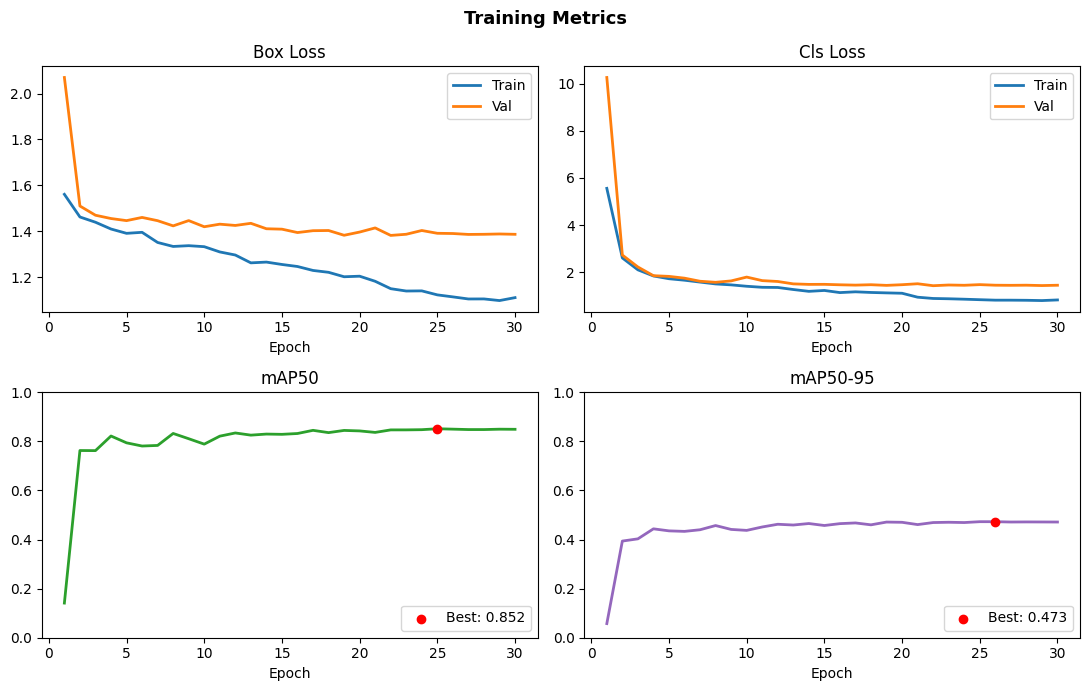

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "/content/drive/MyDrive/TEST/yolocobacoba00-4/results.csv"

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
fig.suptitle("Training Metrics", fontsize=13, fontweight="bold")

# 1. Box Loss
axes[0, 0].plot(df["epoch"], df["train/box_loss"], label="Train", linewidth=2)
axes[0, 0].plot(df["epoch"], df["val/box_loss"], label="Val", linewidth=2)
axes[0, 0].set_title("Box Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].legend()

# 2. Cls Loss
axes[0, 1].plot(df["epoch"], df["train/cls_loss"], label="Train", linewidth=2)
axes[0, 1].plot(df["epoch"], df["val/cls_loss"], label="Val", linewidth=2)
axes[0, 1].set_title("Cls Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].legend()

# 3. mAP50
best_50 = df["metrics/mAP50(B)"].max()
ep_50 = df.loc[df["metrics/mAP50(B)"].idxmax(), "epoch"]
axes[1, 0].plot(df["epoch"], df["metrics/mAP50(B)"], color="#2ca02c", linewidth=2)
axes[1, 0].scatter(ep_50, best_50, color="red", zorder=5, label=f"Best: {best_50:.3f}")
axes[1, 0].set_title("mAP50")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylim(0, 1.0)
axes[1, 0].legend(loc="lower right")

# 4. mAP50-95
best_95 = df["metrics/mAP50-95(B)"].max()
ep_95 = df.loc[df["metrics/mAP50-95(B)"].idxmax(), "epoch"]
axes[1, 1].plot(df["epoch"], df["metrics/mAP50-95(B)"], color="#9467bd", linewidth=2)
axes[1, 1].scatter(ep_95, best_95, color="red", zorder=5, label=f"Best: {best_95:.3f}")
axes[1, 1].set_title("mAP50-95")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylim(0, 1.0)
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/TEST/ringkasan_metrik_penting.png", dpi=300)
plt.show()